In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("fetal_health.csv")

print("Dataset shape:", df.shape)
print("\nFetal health classifications:")
print(df["fetal_health"].value_counts().sort_index())

Dataset shape: (2126, 22)

Fetal health classifications:
fetal_health
1.0    1655
2.0     295
3.0     176
Name: count, dtype: int64


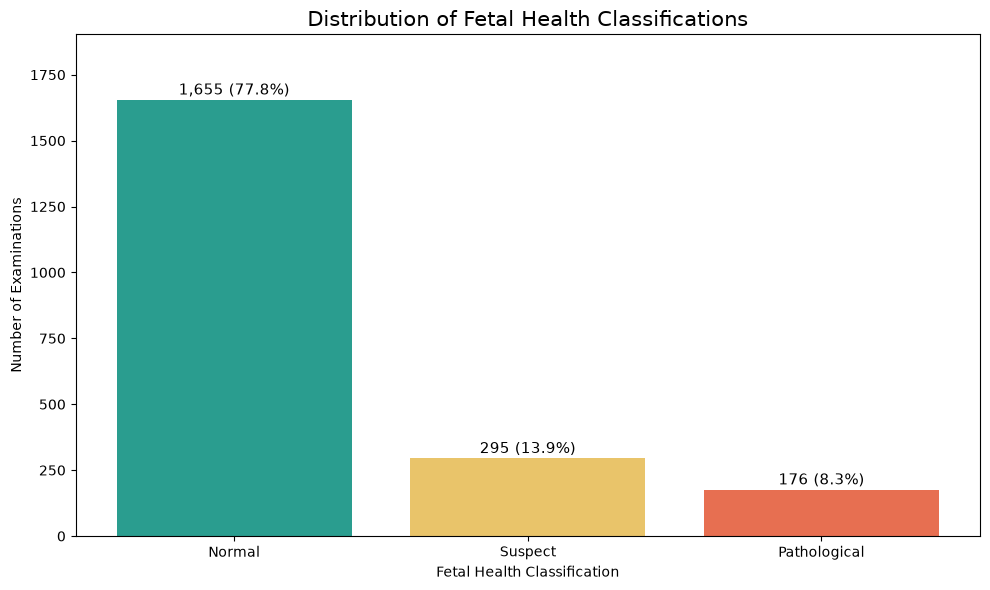

In [2]:
#graph 1 fetal health classification distribution

health_counts = df["fetal_health"].value_counts().sort_index()

labels = ["Normal", "Suspect", "Pathological"]
colors = ["#2A9D8F", "#E9C46A", "#E76F51"]

plt.figure(figsize=(10, 6))

bars = plt.bar(labels, health_counts.values, color=colors)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 20,
        f"{int(height):,} ({height / len(df) * 100:.1f}%)",
        ha="center",
        fontsize=11
    )

plt.title("Distribution of Fetal Health Classifications", fontsize=15)
plt.xlabel("Fetal Health Classification")
plt.ylabel("Number of Examinations")
plt.ylim(0, max(health_counts.values) * 1.15)
plt.tight_layout()

plt.show()

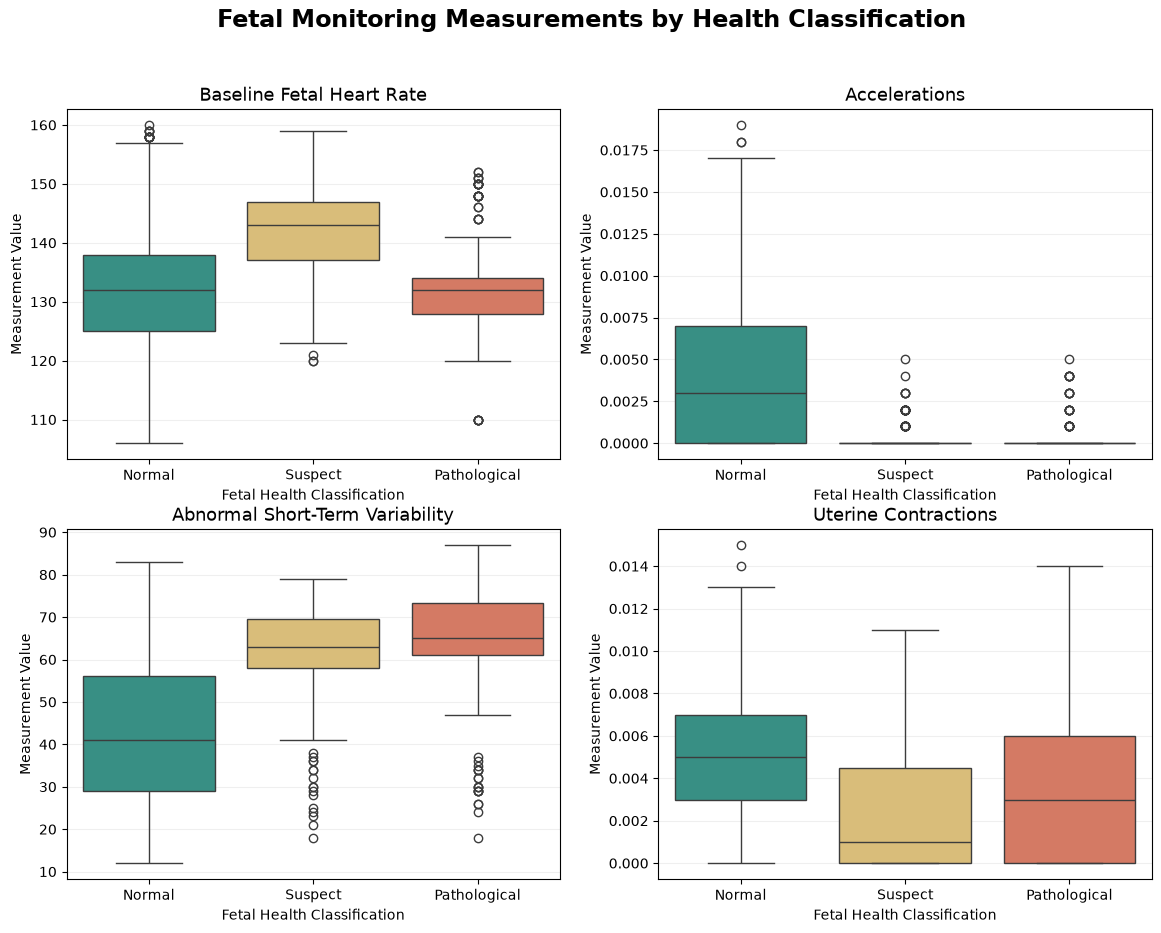

In [3]:
#graph 2 fetal monitoring measurements by health classifications

health_labels = {
    1.0: "Normal",
    2.0: "Suspect",
    3.0: "Pathological"
}

df["Health_Status"] = df["fetal_health"].map(health_labels)

features = {
    "baseline value": "Baseline Fetal Heart Rate",
    "accelerations": "Accelerations",
    "abnormal_short_term_variability": "Abnormal Short-Term Variability",
    "uterine_contractions": "Uterine Contractions"
}

colors = ["#2A9D8F", "#E9C46A", "#E76F51"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (column, title) in zip(axes.flatten(), features.items()):
    sns.boxplot(
        data=df,
        x="Health_Status",
        y=column,
        order=["Normal", "Suspect", "Pathological"],
        hue="Health_Status",
        hue_order=["Normal", "Suspect", "Pathological"],
        palette=colors,
        legend=False,
        ax=ax
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Fetal Health Classification")
    ax.set_ylabel("Measurement Value")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Fetal Monitoring Measurements by Health Classification",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout
plt.show()

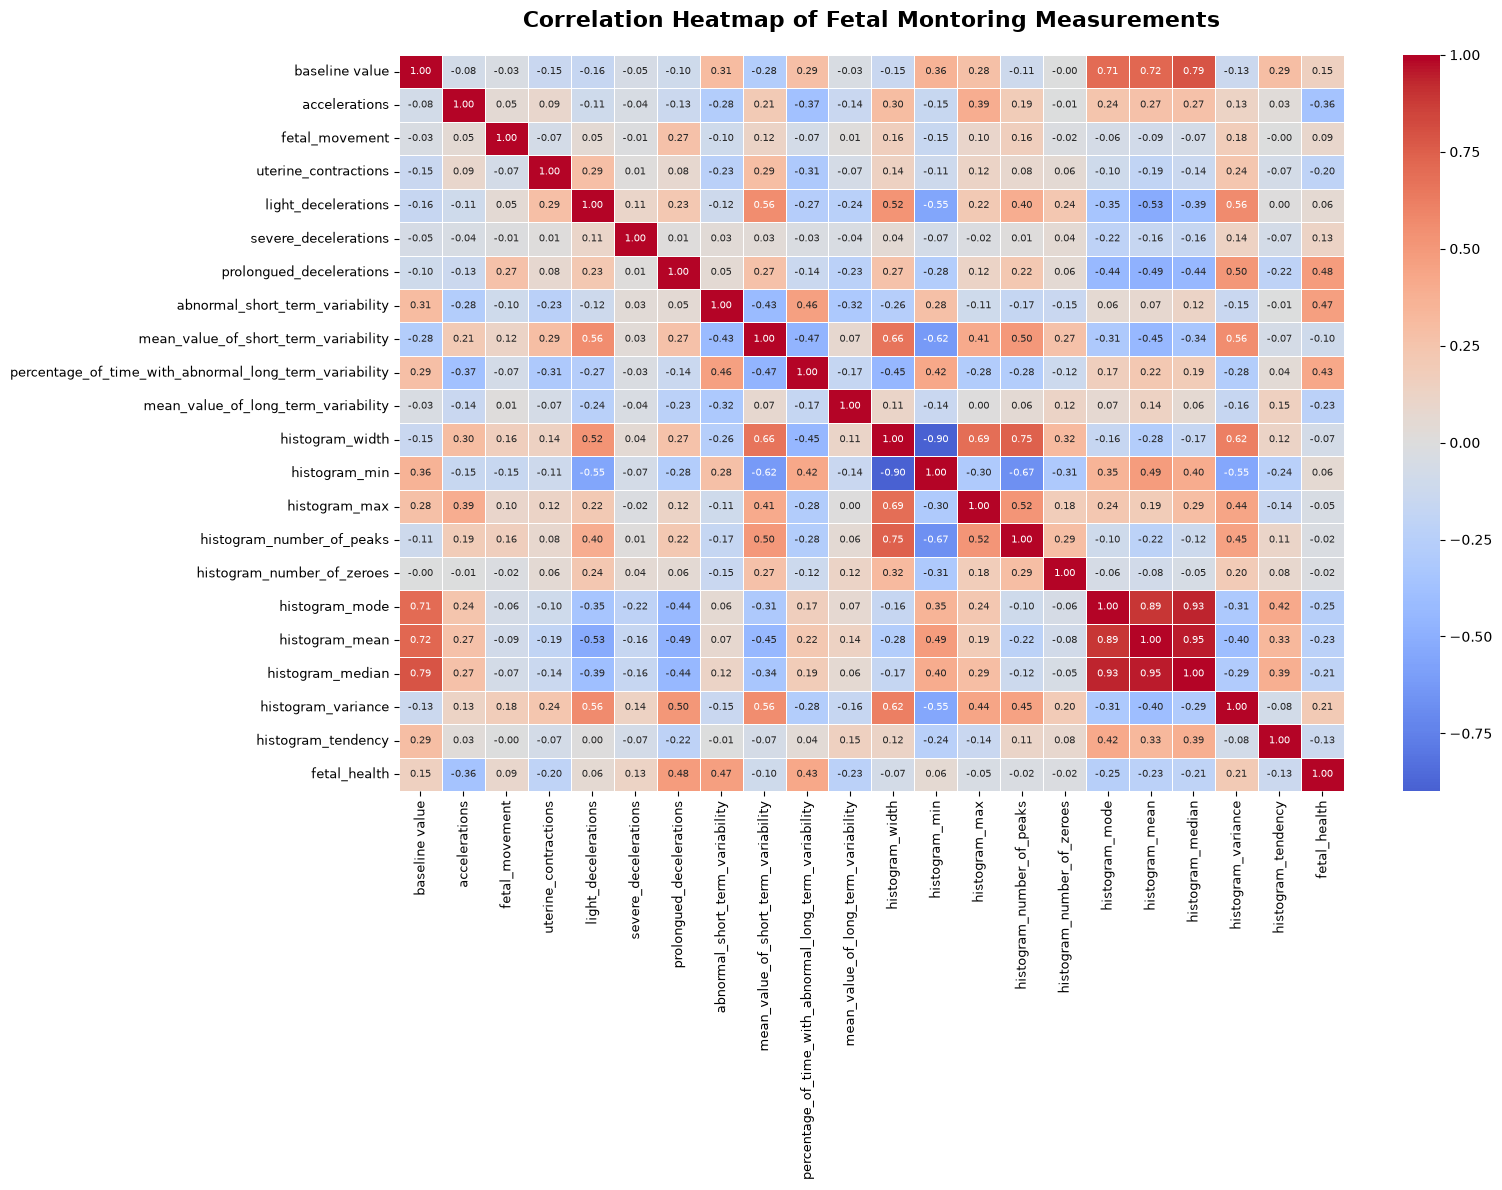

In [4]:
#graph 3 correlation heatmap

#select numerical variables
numeric_df = df.select_dtypes(include="number")

#calculate correlation matrix
correlation_matrix = numeric_df.corr()

#create heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 7}
)

plt.title(
    "Correlation Heatmap of Fetal Montoring Measurements",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

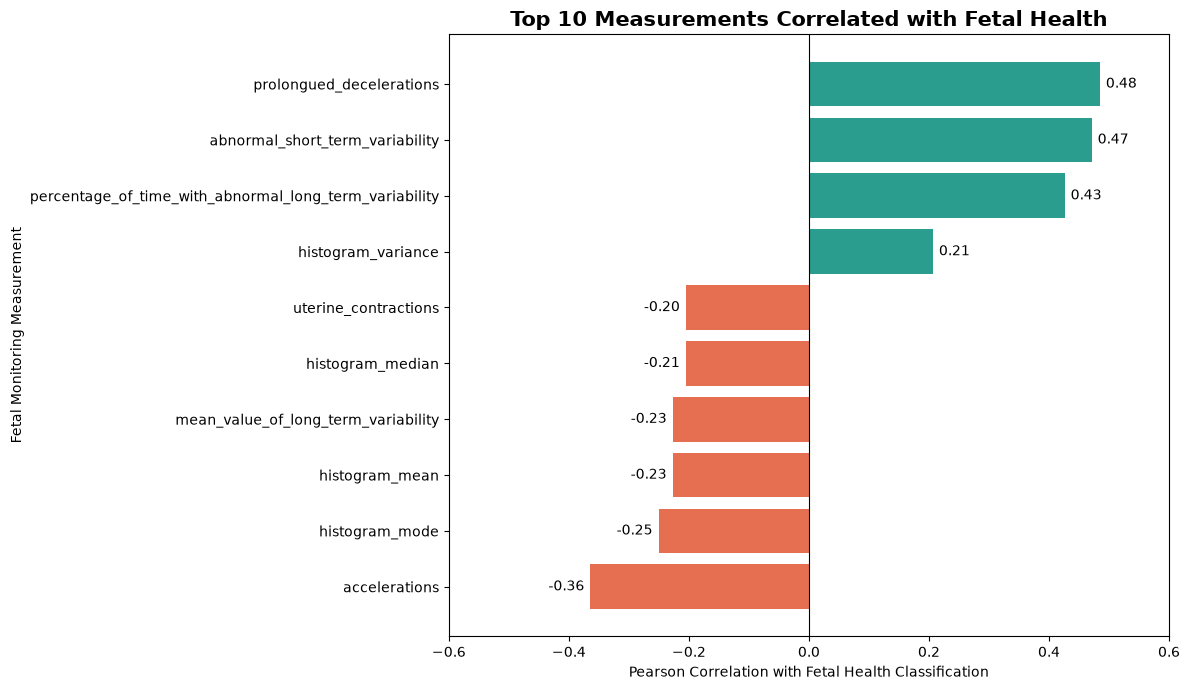

In [5]:
#graph 4 top 10 correlations with fetal health

#calculate correlations with the target variable
health_correlations = (
    df.select_dtypes(include="number")
    .corr()["fetal_health"]
    .drop("fetal_health")
)

#choose 10 strongest correlations
top_correlations = health_correlations.loc[
    health_correlations.abs().nlargest(10).index
].sort_values()

#colors for correlation
colors = [
    "#2A9D8F" if value > 0 else "#E76F51"
    for value in top_correlations
]

#create chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_correlations.index,
    top_correlations.values,
    color=colors
)

# Add correlation labels
for bar in bars:
    value = bar.get_width()

    plt.text(
        value + (0.01 if value >= 0 else -0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=10
    )

plt.axvline(0, color="black", linewidth=0.8)

plt.title(
    "Top 10 Measurements Correlated with Fetal Health",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Pearson Correlation with Fetal Health Classification")
plt.ylabel("Fetal Monitoring Measurement")
plt.xlim(-0.6, 0.6)

plt.tight_layout()
plt.show()


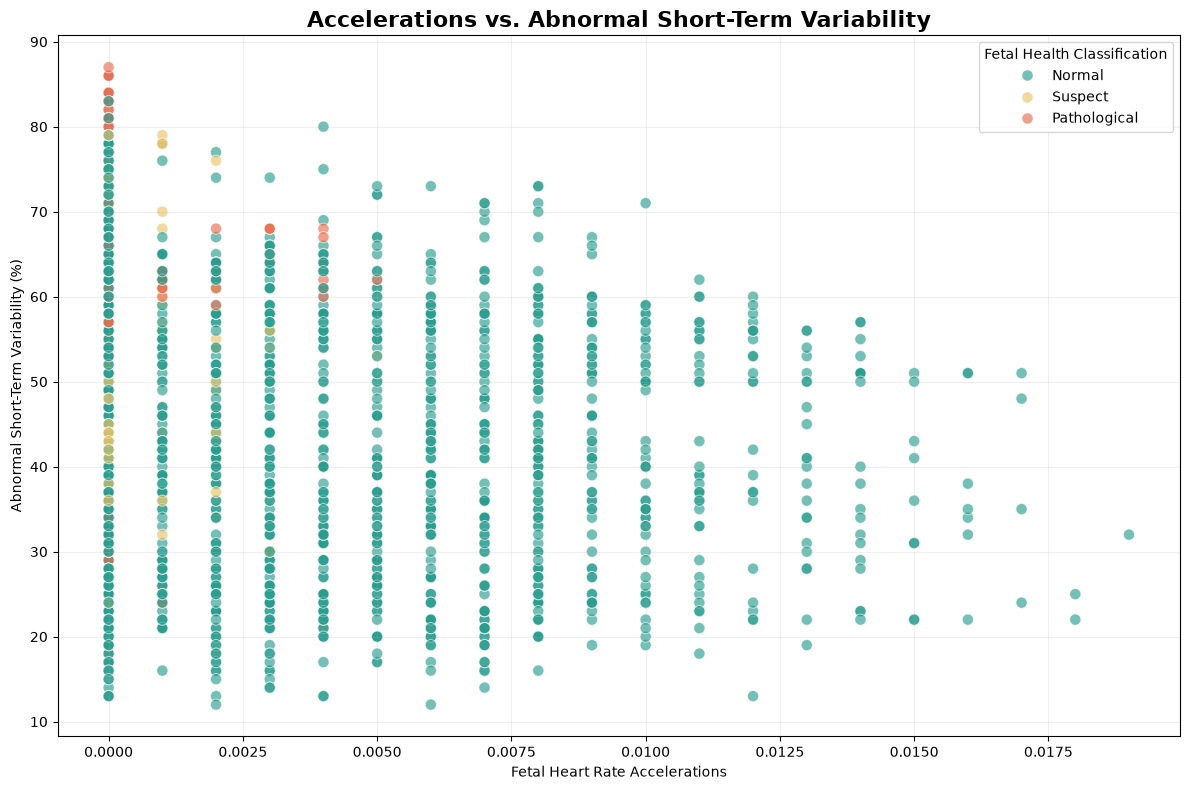

In [6]:
#graph 5 fetal monitoring patterns by health classification

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x="accelerations",
    y="abnormal_short_term_variability",
    hue="Health_Status",
    hue_order=["Normal", "Suspect", "Pathological"],
    palette={
        "Normal": "#2A9D8F",
        "Suspect": "#E9C46A",
        "Pathological": "#E76F51"
    },
    alpha=0.65,
    s=65
)

plt.title(
    "Accelerations vs. Abnormal Short-Term Variability",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Fetal Heart Rate Accelerations")
plt.ylabel("Abnormal Short-Term Variability (%)")

plt.legend(
    title="Fetal Health Classification",
    loc="upper right"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

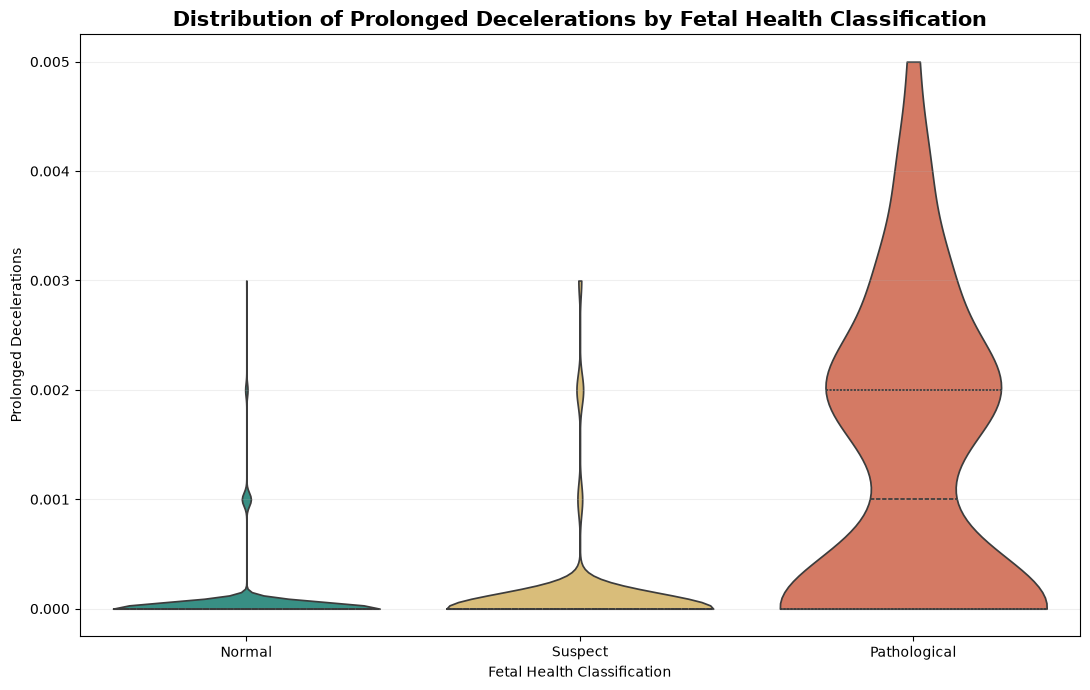

In [7]:
#graph 6 prolonged decelerations by fetal health classification

plt.figure(figsize=(11, 7))

sns.violinplot(
    data=df,
    x="Health_Status",
    y="prolongued_decelerations",
    order=["Normal", "Suspect", "Pathological"],
    hue="Health_Status",
    palette={
        "Normal": "#2A9D8F",
        "Suspect": "#E9C46A",
        "Pathological": "#E76F51"
    },
    legend=False,
    inner="quart",
    cut=0
)

plt.title(
    "Distribution of Prolonged Decelerations by Fetal Health Classification",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Fetal Health Classification")
plt.ylabel("Prolonged Decelerations")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
